# Практична робота № 4. Відкриті міські дані та індикатори сталості
## Варіант 2: якість повітря в районах Києва, 2023 (PM2.5)

**Питання дослідження (внутрішньоміська нерівність).** Який район Києва найчистіший, а який
найзабрудненіший за середньорічною концентрацією PM2.5 у 2023 р.? Чи значуща різниця між ними
з огляду на повноту даних районів?

**Дані.** Набір data.gov.ua «Щогодинні концентрації та індекс якості атмосферного повітря для
дрібнодисперсного пилу фракції 2.5 мікронів в районах населених пунктів України» (розпорядник —
ГО «SaveDnipro», ліцензія CC BY). Для звірки використано міський ряд Києва з набору
«… в населених пунктах України».

**Конвеєр:** завантаження → очищення → оцінка якості даних → обчислення індикаторів →
візуалізація → експорт → творча частина → висновки.

Відмінність від прикладу Харкова: тут не один часовий ряд, а **10 рядів — по одному на район**.
Тому всі кроки виконуються для кожного району (стовпці таблиці або `groupby` за районом).

### Крок 3. Імпорт бібліотек і налаштування

In [1]:
from pathlib import Path

import numpy as np  # встановлюється разом із pandas; потрібен для бутстрепу
import pandas as pd
import matplotlib.pyplot as plt

# Шляхи відносно кореня папки pr4 (ноутбук лежить у notebooks/)
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "reports" / "figures"
PROCESSED.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

YEAR = 2023            # варіант 2: дані районів лише за 2023 рік
CITY_NAME = "Київ"
REGION_NAME = "Київ"   # у довіднику міст Київ має region_name «Київ»
VALID_HOURS = 18       # доба дійсна, якщо є ≥ 18 з 24 годинних вимірів

# Нормативи для порівняння, мкг/м³
WHO_ANNUAL = 5       # ВООЗ 2021, середньорічна
WHO_DAILY = 15       # ВООЗ 2021, середньодобова
EU_ANNUAL_2030 = 10  # ЄС з 2030 р., середньорічна
EU_DAILY_2030 = 25   # ЄС з 2030 р., середньодобова
EU_DAILY_ALLOWED = 18  # ЄС-2030: не більше 18 діб > 25 мкг/м³ на рік

pd.set_option("display.max_columns", 20)
print("pandas", pd.__version__)
print("Файли в data/raw:",
      sorted(p.name for p in RAW.glob("*.csv")))

pandas 3.1.0
Файли в data/raw: ['saveecobot_aqi_cities.csv', 'saveecobot_cities_pm25_and_aqi_pm25_2021.csv', 'saveecobot_cities_pm25_and_aqi_pm25_2022.csv', 'saveecobot_cities_pm25_and_aqi_pm25_2023.csv', 'saveecobot_city_districts.csv', 'saveecobot_city_districts_pm25_and_aqi_pm25_2023.csv']


### Крок 4. Довідники: ідентифікатор міста і районів

Спершу, як у прикладі, знаходимо `city_id` Києва в довіднику міст (пошук за назвою, областю і типом
та перевірка `assert`). Потім у довіднику районів `saveecobot_city_districts.csv` відбираємо райони
**за ключем** `city_id`, а не за назвою: це та сама структура «довідник + таблиця фактів».

In [2]:
cities = pd.read_csv(RAW / "saveecobot_aqi_cities.csv",
                     encoding="utf-8")
match = cities[(cities["city_name"] == CITY_NAME)
               & (cities["region_name"] == REGION_NAME)
               & (cities["type_name"] == "місто")]
assert len(match) == 1, (
    f"Знайдено {len(match)} рядків — уточніть умову пошуку")
CITY_ID = int(match["id"].iloc[0])
SLUG = match["url_slug"].iloc[0]  # латинська назва, "kyiv"
print(f"{CITY_NAME}: city_id = {CITY_ID}, slug = {SLUG}")
match

Київ: city_id = 2, slug = kyiv


,id,url_slug,type_name,city_name,region_name,koatuu,katottg
1,2,kyiv,місто,Київ,Київ,8.000000e+09,UA80000000000093317


In [3]:
districts = pd.read_csv(RAW / "saveecobot_city_districts.csv",
                        encoding="utf-8")
print(districts.shape)
districts.head()

(79, 7)


,id,region_name,city_type_name,city_name,district_name,city_id,koatuu
0,4,Дніпропетровська область,місто,Дніпро,Амур-Нижньодніпровський район,1,1210136300
1,5,Дніпропетровська область,місто,Дніпро,Шевченківський район,1,1210136600
2,6,Дніпропетровська область,місто,Дніпро,Соборний район,1,1210136900
3,7,Дніпропетровська область,місто,Дніпро,Індустріальний район,1,1210137200
4,8,Дніпропетровська область,місто,Дніпро,Центральний район,1,1210137500


In [4]:
# Райони свого міста — за ключем city_id
kyiv_districts = (districts[districts["city_id"] == CITY_ID]
                  .sort_values("id"))
assert len(kyiv_districts) > 0, (
    "Районів не знайдено — перевірте city_id у довіднику районів")
assert (kyiv_districts["city_name"] == CITY_NAME).all(), (
    "За city_id знайдено райони іншого міста")
assert kyiv_districts["district_name"].is_unique, (
    "Назви районів повторюються")

DISTRICT_IDS = kyiv_districts["id"].astype(int).tolist()
NAMES = dict(zip(kyiv_districts["id"].astype(int),
                 kyiv_districts["district_name"]))
print(f"Районів: {len(DISTRICT_IDS)}; district_id: {DISTRICT_IDS}")
kyiv_districts

Районів: 10; district_id: [95, 96, 97, 98, 99, 100, 101, 102, 103, 104]


,id,region_name,city_type_name,city_name,district_name,city_id,koatuu
69,95,Київ,місто,Київ,Голосіївський район,2,8036100000
70,96,Київ,місто,Київ,Дарницький район,2,8036300000
71,97,Київ,місто,Київ,Деснянський район,2,8036400000
72,98,Київ,місто,Київ,Дніпровський район,2,8036600000
73,99,Київ,місто,Київ,Оболонський район,2,8038000000
74,100,Київ,місто,Київ,Печерський район,2,8038200000
75,101,Київ,місто,Київ,Подільський район,2,8038500000
76,102,Київ,місто,Київ,Святошинський район,2,8038600000
77,103,Київ,місто,Київ,Солом'янський район,2,8038900000
78,104,Київ,місто,Київ,Шевченківський район,2,8039100000


### Крок 5. Завантаження щогодинних даних районів

Файл за рік містить райони **всіх** міст (Київ, Львів, …). Читаємо лише потрібні стовпці з явними
типами і одразу залишаємо райони Києва (`isin` — «значення є у списку»).

In [5]:
def read_districts(year: int) -> pd.DataFrame:
    name = f"saveecobot_city_districts_pm25_and_aqi_pm25_{year}.csv"
    df = pd.read_csv(
        RAW / name,
        encoding="utf-8",   # кодування файлу
        sep=",",            # роздільник стовпців
        usecols=["district_id", "pm25", "logged_at"],
        dtype={"district_id": "int32", "pm25": "float64",
               "logged_at": "string"},
    )
    print(f"{year}: усього {len(df):>9,} рядків", end=" → ")
    df = df[df["district_id"].isin(DISTRICT_IDS)]
    print(f"для районів міста {len(df):,}")
    return df

raw = read_districts(YEAR)
raw.info()

2023: усього   331,409 рядків → для районів міста 87,565
<class 'pandas.DataFrame'>
RangeIndex: 87565 entries, 243844 to 331408
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   district_id  87565 non-null  int32  
 1   pm25         87500 non-null  float64
 2   logged_at    87565 non-null  string 
dtypes: float64(1), int32(1), string(1)
memory usage: 1.7 MB


In [6]:
# Скільки рядків має кожен район (повний рік — 8760 годин)
(raw["district_id"].map(NAMES).value_counts()
 .rename_axis("район").sort_index().to_frame("рядків"))

,рядків
район,
Голосіївський район,8759
Дарницький район,8759
Деснянський район,8741
Дніпровський район,8760
Оболонський район,8759
Печерський район,8753
Подільський район,8757
Святошинський район,8758
Солом'янський район,8760


### Крок 6. Очищення даних

Ті самі перевірки, що й у прикладі, але **для кожного району окремо**: пропуски (`NULL` → `NaN`),
фізично неможливі значення, повні дублікати рядків і повтори години. Повтор години тепер означає
повтор пари «район + година»: в одну годину різні райони мають різні значення, і це не дублікат.

In [7]:
df = raw.copy()

# 1) Текст дати-часу → тип datetime (явний формат)
df["logged_at"] = pd.to_datetime(df["logged_at"],
                                 format="%Y-%m-%d %H:%M:%S")
df["район"] = df["district_id"].map(NAMES)

# 2)–4) Проблеми якості за районами
by = df["район"]
checks = pd.DataFrame({
    "рядків": by.value_counts(),
    "NULL_pm25": df["pm25"].isna().groupby(by).sum(),
    "неможливих": ((df["pm25"] < 0) | (df["pm25"] > 1000))
                  .groupby(by).sum(),
    "повних_дублікатів": df.duplicated().groupby(by).sum(),
    "повторів_години": (df.duplicated(subset=["district_id",
                                              "logged_at"])
                        .groupby(by).sum()),
}).sort_index()
checks.loc["усього"] = checks.sum()

print("Позначок не на початку години:",
      (df["logged_at"] != df["logged_at"].dt.floor("h")).sum())
print("Позначок поза", YEAR, "роком:",
      (df["logged_at"].dt.year != YEAR).sum())
checks

Позначок не на початку години:

 0


Позначок поза 2023 роком: 0


,рядків,NULL_pm25,неможливих,повних_дублікатів,повторів_години
район,,,,,
Голосіївський район,8759,1,0,0,0
Дарницький район,8759,2,0,0,0
Деснянський район,8741,40,0,0,0
Дніпровський район,8760,1,0,0,0
Оболонський район,8759,1,0,0,0
Печерський район,8753,10,0,0,0
Подільський район,8757,6,0,0,0
Святошинський район,8758,2,0,0,0
Солом'янський район,8760,1,0,0,0


In [8]:
# Коли трапляються проблеми: дати повторів години і NULL
dup_mask = df.duplicated(subset=["district_id", "logged_at"])
print("Повтори години за датами:")
print(df.loc[dup_mask, "logged_at"].dt.date
      .value_counts().sort_index().to_string())
print("\nNULL за датами (10 дат із найбільшою кількістю):")
print(df.loc[df["pm25"].isna(), "logged_at"].dt.date
      .value_counts().head(10).to_string())

Повтори години за датами:
Series([], )

NULL за датами (10 дат із найбільшою кількістю):
logged_at
2023-03-26    10
2023-01-12     5
2023-01-09     4
2023-01-18     4
2023-01-21     4
2023-01-13     3
2023-01-25     3
2023-02-01     3
2023-02-02     3
2023-01-30     2


In [9]:
# одна година району — один вимір; лише можливі значення; за часом
df = (df.drop_duplicates(subset=["district_id", "logged_at"])
        .loc[lambda d: d["pm25"].between(0, 1000)]
        .sort_values(["district_id", "logged_at"])
        .set_index("logged_at"))
print(len(raw), "→", len(df), "рядків після очищення")
df.groupby("район")["pm25"].describe().round(1)

87565 → 87500 рядків після очищення


,count,mean,std,min,25%,50%,75%,max
район,,,,,,,,
Голосіївський район,8758.0,9.6,6.2,0.8,4.9,8.0,12.6,50.7
Дарницький район,8757.0,12.4,8.2,1.0,6.6,10.7,16.3,107.2
Деснянський район,8701.0,12.0,6.6,1.0,7.0,10.4,15.4,55.9
Дніпровський район,8759.0,10.3,6.7,1.1,5.6,8.7,13.3,64.6
Оболонський район,8758.0,9.3,6.1,0.8,4.8,7.8,12.2,73.2
Печерський район,8743.0,11.2,7.4,0.2,5.5,9.7,15.5,63.9
Подільський район,8751.0,9.3,5.9,0.8,5.0,7.8,11.9,51.6
Святошинський район,8756.0,9.9,6.2,0.8,5.4,8.5,12.9,55.0
Солом'янський район,8759.0,13.5,9.1,0.7,6.5,11.1,18.5,81.2


### Крок 7. Оцінка якості даних: повнота і пропуски

Перебудовуємо дані у «широку» таблицю: рядки — **усі** 8760 годин року, стовпці — райони.
`reindex(FULL_HOURS)` додає години, для яких немає виміру, зі значенням `NaN`. Так повнота кожного
району рахується від повного року, навіть якщо ряд району почався пізніше чи закінчився раніше.

In [10]:
FULL_HOURS = pd.date_range(f"{YEAR}-01-01", f"{YEAR + 1}-01-01",
                           freq="h", inclusive="left")
wide = (df.reset_index()
          .pivot(index="logged_at", columns="район", values="pm25")
          .reindex(FULL_HOURS))
wide.index.name = "logged_at"

# 1 — у цю годину є вимір, 0 — немає
hours = wide.notna().astype(int)
print("Таблиця годин × районів:", wide.shape)

# Повнота за місяць, % — формула (1); останній рядок — за рік
completeness_table = (hours.resample("MS").mean() * 100).round(1)
completeness_table.index = completeness_table.index.month
completeness_table.index.name = "місяць"
completeness_table.loc["рік"] = (hours.mean() * 100).round(1)
completeness_table

Таблиця годин × районів: (8760, 10)


район,Голосіївський район,Дарницький район,Деснянський район,Дніпровський район,Оболонський район,Печерський район,Подільський район,Святошинський район,Солом'янський район,Шевченківський район
місяць,,,,,,,,,,
1,100.0,99.9,94.1,100.0,100.0,98.0,99.9,99.7,100.0,100.0
2,100.0,100.0,98.1,100.0,100.0,100.0,99.1,100.0,100.0,100.0
3,99.7,99.7,99.7,99.9,99.7,99.7,99.7,99.7,99.9,99.7
4,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
5,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
6,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
7,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
8,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
9,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0


In [11]:
# Найдовші пропуски кожного району — прийом shift() + cumsum()
def longest_gaps(has_data: pd.Series, n: int = 3) -> pd.DataFrame:
    missing = has_data.eq(0)
    gap_id = (missing != missing.shift()).cumsum()
    return (missing[missing].groupby(gap_id[missing])
            .agg(початок=lambda s: s.index.min(),
                 тривалість_год="size")
            .sort_values("тривалість_год", ascending=False)
            .head(n)
            .reset_index(drop=True))

gaps = pd.concat({name: longest_gaps(hours[name])
                  for name in hours.columns},
                 names=["район", "№"])
gaps

початок  тривалість_год
район                №                                    
Голосіївський район  0 2023-03-26 02:00:00               2
Дарницький район     0 2023-03-26 02:00:00               2
                     1 2023-01-30 17:00:00               1
Деснянський район    0 2023-01-12 11:00:00               6
                     1 2023-01-10 14:00:00               4
                     2 2023-01-21 10:00:00               4
Дніпровський район   0 2023-03-26 02:00:00               1
Оболонський район    0 2023-03-26 02:00:00               2
Печерський район     0 2023-01-09 19:00:00               4
                     1 2023-01-12 10:00:00               4
                     2 2023-03-26 02:00:00               2
Подільський район    0 2023-02-07 04:00:00               4
                     1 2023-03-26 02:00:00               2
                     2 2023-01-13 14:00:00               1
Святошинський район  0 2023-03-26 02:00:00               2
                     1 2023-01-21 04:00:00               1
                     2 2023-01-21 06:00:00               1
Солом'янський район  0 2023-03-26 02:00:00               1
Шевченківський район 0 2023-03-26 02:00:00               2

In [12]:
# Пропуски одночасно в усіх районах — ознака збою системи збору
# або особливості часу (перехід на літній час), а не району
all_missing = hours.sum(axis=1).eq(0)
print("Годин без даних у жодному районі:", int(all_missing.sum()))
print(all_missing[all_missing].index.to_series()
      .dt.strftime("%Y-%m-%d %H:%M").to_string(index=False))

Годин без даних у жодному районі: 1
logged_at
2023-03-26 02:00
Freq: h


### Крок 8. Середньодобові значення

Формули (2) і (3): середнє наявних годин доби; доба дійсна, якщо вимірів ≥ 18. Операції
`resample("D")` над широкою таблицею виконуються одразу для всіх районів (кожен стовпець окремо).

In [13]:
daily_mean = wide.resample("D").mean()    # c̄_d для кожного району
daily_count = wide.resample("D").count()  # n_d — кількість годин
valid = daily_count >= VALID_HOURS
daily_mean = daily_mean.where(valid)      # недійсні доби → NaN

print("Діб у році:", len(daily_mean))
(~valid).sum().to_frame("недійсних_діб")

Діб у році: 365


,недійсних_діб
район,
Голосіївський район,0
Дарницький район,0
Деснянський район,1
Дніпровський район,0
Оболонський район,0
Печерський район,0
Подільський район,0
Святошинський район,0
Солом'янський район,0


In [14]:
# «Довга» таблиця діб: дата, район, середнє, години, ознака дійсності
def to_long(table: pd.DataFrame, value_name: str) -> pd.DataFrame:
    return (table.rename_axis(index="date", columns="район")
                 .reset_index()
                 .melt(id_vars="date", var_name="район",
                       value_name=value_name))

daily = (to_long(daily_mean, "pm25_mean")
         .merge(to_long(daily_count, "hours"), on=["date", "район"]))
daily["valid"] = daily["hours"] >= VALID_HOURS
print(daily.shape)
daily.head()

(3650, 5)


,date,район,pm25_mean,hours,valid
0,2023-01-01,Голосіївський район,7.787133,24,True
1,2023-01-02,Голосіївський район,15.217975,24,True
2,2023-01-03,Голосіївський район,14.516362,24,True
3,2023-01-04,Голосіївський район,7.567146,24,True
4,2023-01-05,Голосіївський район,10.148779,24,True


### Крок 9. Обчислення індикаторів

Той самий код, що й у прикладі, але групування не за роком, а **за районом**
(`groupby("район")`). Формули (4)–(8): середньорічна з дійсних діб, повнота року, доби з
перевищенням, кратність і рівень ВООЗ. Додано порівняння з обома вимогами ЄС-2030.

In [15]:
def who_level(x: float) -> str:
    """Рівень за проміжними цілями ВООЗ (Interim Targets)."""
    levels = [(5, "настанова ВООЗ"), (10, "IT-4"),
              (15, "IT-3"), (25, "IT-2"), (35, "IT-1")]
    for limit, name in levels:
        if x <= limit:
            return name
    return "гірше IT-1"

ind = daily.groupby("район").agg(
    середньорічна_pm25=("pm25_mean", "mean"),
    дійсних_діб=("valid", "sum"),
    діб_у_році=("valid", "size"),
    діб_понад_15=("pm25_mean", lambda s: (s > WHO_DAILY).sum()),
    діб_понад_25=("pm25_mean",
                  lambda s: (s > EU_DAILY_2030).sum()),
)
ind["повнота_%"] = (ind["дійсних_діб"] / ind["діб_у_році"]
                    * 100).round(1)
ind["надійно"] = ind["повнота_%"] >= 90
ind["рівень_ВООЗ"] = ind["середньорічна_pm25"].apply(who_level)
ind["у_разів_вище_ВООЗ"] = (ind["середньорічна_pm25"]
                            / WHO_ANNUAL).round(1)
ind["ЄС_річна_≤10"] = ind["середньорічна_pm25"] <= EU_ANNUAL_2030
ind["ЄС_добова_≤18_діб"] = ind["діб_понад_25"] <= EU_DAILY_ALLOWED

ind = ind.sort_values("середньорічна_pm25")  # від найчистішого
annual = ind["середньорічна_pm25"].copy()   # неокруглені значення
ind["середньорічна_pm25"] = ind["середньорічна_pm25"].round(1)
ind.index.name = "район"

CLEANEST, DIRTIEST = annual.index[0], annual.index[-1]
print(f"Найчистіший район: {CLEANEST} ({annual[CLEANEST]:.1f} мкг/м³)")
print(f"Найзабрудненіший район: {DIRTIEST} ({annual[DIRTIEST]:.1f} мкг/м³)")
ind

Найчистіший район: Подільський район (9.3 мкг/м³)
Найзабрудненіший район: Солом'янський район (13.5 мкг/м³)


,середньорічна_pm25,дійсних_діб,діб_у_році,діб_понад_15,діб_понад_25,повнота_%,надійно,рівень_ВООЗ,у_разів_вище_ВООЗ,ЄС_річна_≤10,ЄС_добова_≤18_діб
район,,,,,,,,,,,
Подільський район,9.3,365,365,47,1,100.0,True,IT-4,1.9,True,True
Оболонський район,9.3,365,365,57,3,100.0,True,IT-4,1.9,True,True
Голосіївський район,9.6,365,365,59,2,100.0,True,IT-4,1.9,True,True
Святошинський район,9.9,365,365,51,6,100.0,True,IT-4,2.0,True,True
Дніпровський район,10.3,365,365,58,7,100.0,True,IT-3,2.1,False,True
Шевченківський район,10.6,365,365,74,14,100.0,True,IT-3,2.1,False,True
Печерський район,11.3,365,365,93,13,100.0,True,IT-3,2.3,False,True
Деснянський район,12.0,364,365,86,12,99.7,True,IT-3,2.4,False,True
Дарницький район,12.4,365,365,103,21,100.0,True,IT-3,2.5,False,False


**Ручна перевірка (для звіту).** Для найчистішого і найзабрудненішого району підставте числа з
таблиці у формули (5), (7), (8), (6), як у прикладі для Харкова 2021 р.:
повнота = дійсних_діб / 365 · 100 %; кратність = середньорічна / 5; рівень — за межами IT-1…IT-4.

### Крок 10. Візуалізація

Три обов'язкові графіки, адаптовані для районів: середньомісячна концентрація кожного району
(формула 9), середньорічна концентрація районів проти нормативів, добовий профіль (формула 10)
за всіма годинними вимірами районів міста.

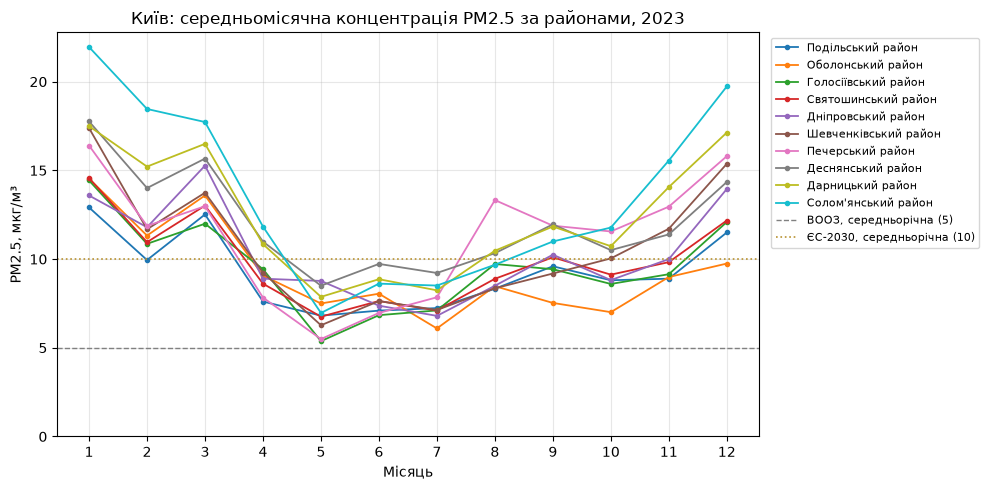

In [16]:
monthly = daily_mean.resample("MS").mean()   # формула (9), кожен район
order = list(annual.index)                   # від найчистішого
colors = plt.get_cmap("tab10")

fig, ax = plt.subplots(figsize=(10, 5))
for i, name in enumerate(order):
    ax.plot(monthly.index.month, monthly[name], marker="o", ms=3,
            lw=1.3, color=colors(i % 10), label=name)
ax.axhline(WHO_ANNUAL, ls="--", color="gray", lw=1,
           label="ВООЗ, середньорічна (5)")
ax.axhline(EU_ANNUAL_2030, ls=":", color="#B8912F", lw=1.2,
           label="ЄС-2030, середньорічна (10)")
ax.set_ylim(bottom=0)
ax.set_xticks(range(1, 13))
ax.set_xlabel("Місяць")
ax.set_ylabel("PM2.5, мкг/м³")
ax.set_title(f"{CITY_NAME}: середньомісячна концентрація PM2.5 "
             f"за районами, {YEAR}")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES / "monthly_pm25.png", dpi=150)
plt.show()

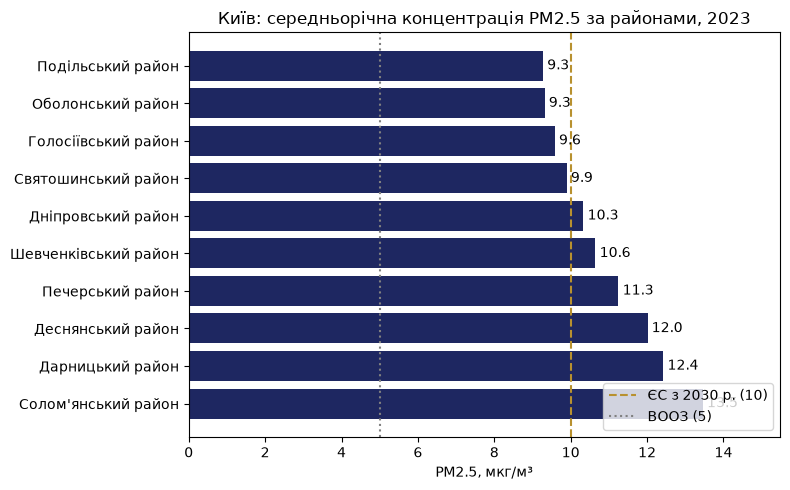

In [17]:
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(order, annual[order], color="#1E2761")
ax.bar_label(bars, fmt="%.1f", padding=3)
ax.axvline(EU_ANNUAL_2030, ls="--", color="#B8912F",
           label="ЄС з 2030 р. (10)")
ax.axvline(WHO_ANNUAL, ls=":", color="gray", label="ВООЗ (5)")
ax.invert_yaxis()                      # найчистіший — угорі
ax.set_xlim(0, max(annual.max(), EU_ANNUAL_2030) * 1.15)
ax.set_xlabel("PM2.5, мкг/м³")
ax.set_title(f"{CITY_NAME}: середньорічна концентрація PM2.5 "
             f"за районами, {YEAR}")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIGURES / "annual_pm25.png", dpi=150)
plt.show()

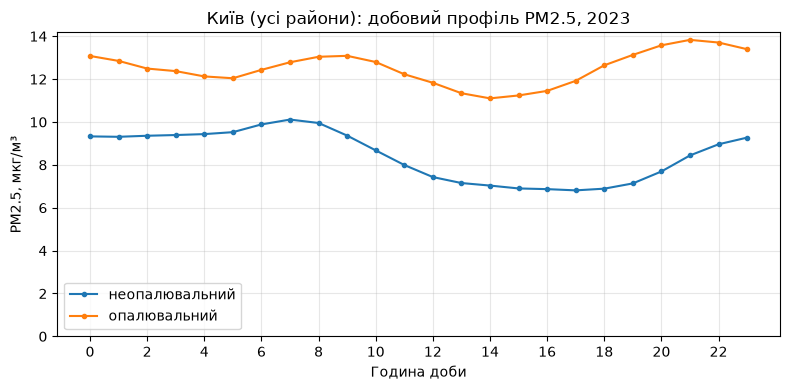

In [18]:
# Добовий профіль: середнє для кожної години доби за всіма вимірами
# районів у опалювальний (жовтень–квітень) і неопалювальний період
heating = df.index.month.isin([10, 11, 12, 1, 2, 3, 4])
profile = (df.groupby([heating, df.index.hour])["pm25"]
             .mean().unstack(0))
profile.columns = ["неопалювальний", "опалювальний"]
ax = profile.plot(figsize=(8, 4), marker=".")
ax.set_xlabel("Година доби")
ax.set_ylabel("PM2.5, мкг/м³")
ax.set_title(f"{CITY_NAME} (усі райони): добовий профіль PM2.5, {YEAR}")
ax.set_xticks(range(0, 24, 2))
ax.set_ylim(bottom=0)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES / "diurnal_profile.png", dpi=150)
plt.show()

### Крок 11. Експорт результатів

Очищені середньодобові дані (довга таблиця: дата, район, середнє, кількість годин, дійсність),
таблиця індикаторів за районами і таблиця повноти. Ці файли невеликі й комітяться в репозиторій.

In [19]:
daily.to_csv(PROCESSED / f"{SLUG}_pm25_daily.csv", index=False)
ind.to_csv(PROCESSED / f"{SLUG}_pm25_indicators.csv")
completeness_table.to_csv(PROCESSED / f"{SLUG}_pm25_completeness.csv")
print("Збережено:",
      sorted(p.name for p in PROCESSED.glob("*.csv")))

Збережено: ['kharkiv_pm25_daily.csv', 'kharkiv_pm25_indicators.csv', 'kyiv_pm25_completeness.csv', 'kyiv_pm25_daily.csv', 'kyiv_pm25_indicators.csv']


## Творча частина (варіант 2): внутрішньоміська нерівність

**Гіпотеза H1.** Найзабрудненіший район Києва має вищу концентрацію PM2.5, ніж найчистіший, і ця
різниця більша за випадкові коливання від доби до доби.
**Нульова гіпотеза H0.** Різниця пояснюється випадковістю: 95 % довірчий інтервал середньої різниці
містить 0.

**Метод.**
1. Розмах середньорічних значень і перевірка впливу повноти: індикатор перераховується лише
   на **спільних дійсних добах** (дійсних в усіх районах одночасно). Якщо ранжування не змінюється,
   різниця не є наслідком різних пропусків.
2. **Парне порівняння діб.** Порівнюємо райони в ті самі доби: погода в місті спільна, тож різниця
   двох районів «очищується» від погодних коливань.
3. **Блоковий бутстреп** для 95 % довірчого інтервалу: випадково з поверненням вибираємо цілі
   тижні (сусідні доби залежні через погоду, тому окремі доби перемішувати не можна) і щоразу
   рахуємо середню різницю. 2,5 % і 97,5 % перцентилі — межі інтервалу.
4. Частка діб, коли район був найчистішим / найбруднішим, і матриця парних різниць усіх районів.
5. Звірка з міським рядом Києва (набір «… в населених пунктах»).

In [20]:
# 1. Розмах і стійкість ранжування до повноти даних
spread = annual[DIRTIEST] - annual[CLEANEST]
print(f"Розмах: {spread:.1f} мкг/м³ "
      f"({spread / annual[CLEANEST] * 100:.0f} % від рівня {CLEANEST})")

common = daily_mean.dropna()   # доби, дійсні в усіх районах
print(f"Спільних дійсних діб: {len(common)} з {len(daily_mean)}")

robust = pd.DataFrame({
    "усі_дійсні_доби": annual,
    "спільні_доби": common.mean(),
})
robust["ранг_усі"] = robust["усі_дійсні_доби"].rank(method="min").astype(int)
robust["ранг_спільні"] = robust["спільні_доби"].rank(method="min").astype(int)
robust["різниця"] = robust["спільні_доби"] - robust["усі_дійсні_доби"]
robust.round(2)

Розмах: 4.2 мкг/м³ (45 % від рівня Подільський район)
Спільних дійсних діб: 364 з 365


,усі_дійсні_доби,спільні_доби,ранг_усі,ранг_спільні,різниця
район,,,,,
Голосіївський район,9.58,9.57,3,3,-0.01
Дарницький район,12.42,12.41,9,9,-0.02
Деснянський район,12.01,12.01,8,8,0.00
Дніпровський район,10.33,10.32,5,5,-0.01
Оболонський район,9.32,9.30,2,2,-0.02
Печерський район,11.25,11.23,7,7,-0.02
Подільський район,9.28,9.26,1,1,-0.02
Святошинський район,9.90,9.89,4,4,-0.01
Солом'янський район,13.46,13.44,10,10,-0.02


In [21]:
# 2–3. Парна різниця найбруднішого і найчистішого районів
def block_bootstrap_ci(diff: pd.Series, n_boot: int = 10_000,
                       seed: int = 42) -> tuple[float, float]:
    """95 % інтервал середньої різниці; ресемплінг цілих тижнів."""
    weeks = diff.groupby(diff.index.to_period("W"))
    sums = weeks.sum().to_numpy()      # сума різниць за тиждень
    counts = weeks.size().to_numpy()   # кількість діб у тижні
    rng = np.random.default_rng(seed)  # seed — відтворюваність
    idx = rng.integers(0, len(sums), size=(n_boot, len(sums)))
    boot = sums[idx].sum(axis=1) / counts[idx].sum(axis=1)
    low, high = np.percentile(boot, [2.5, 97.5])
    return float(low), float(high)

pair = daily_mean[[DIRTIEST, CLEANEST]].dropna()
diff = pair[DIRTIEST] - pair[CLEANEST]
low, high = block_bootstrap_ci(diff)
print(f"Парних дійсних діб: {len(diff)}")
print(f"Середня різниця {DIRTIEST} − {CLEANEST}: {diff.mean():.2f} мкг/м³")
print(f"95 % довірчий інтервал (блоковий бутстреп): [{low:.2f}; {high:.2f}]")
print(f"Діб, коли {DIRTIEST} брудніший: {(diff > 0).mean() * 100:.0f} %")
print("Висновок:", "різниця значуща (0 поза інтервалом)"
      if low > 0 or high < 0 else "різниця незначуща (0 в інтервалі)")

Парних дійсних діб: 365
Середня різниця Солом'янський район − Подільський район: 4.18 мкг/м³
95 % довірчий інтервал (блоковий бутстреп): [3.23; 5.17]
Діб, коли Солом'янський район брудніший: 91 %
Висновок: різниця значуща (0 поза інтервалом)


In [22]:
# 4а. Як часто район був найчистішим / найбруднішим (спільні доби)
share = pd.DataFrame({
    "найчистіший_%": common.idxmin(axis=1).value_counts(normalize=True),
    "найбрудніший_%": common.idxmax(axis=1).value_counts(normalize=True),
}).reindex(order).fillna(0).mul(100).round(1)
share

,найчистіший_%,найбрудніший_%
Подільський район,21.2,0.3
Оболонський район,39.0,1.6
Голосіївський район,19.0,1.1
Святошинський район,3.6,0.0
Дніпровський район,6.9,4.7
Шевченківський район,1.4,1.6
Печерський район,9.1,16.2
Деснянський район,0.0,20.6
Дарницький район,0.0,15.9
Солом'янський район,0.0,37.9


In [23]:
# 4б. Матриця парних різниць: рядок − стовпець, мкг/м³;
# значущі різниці (0 поза 95 % інтервалом) позначено «*»
mean_diff = pd.DataFrame(np.nan, index=order, columns=order)
signif = pd.DataFrame(False, index=order, columns=order)
for a in order:
    for b in order:
        if a == b:
            continue
        d = (daily_mean[a] - daily_mean[b]).dropna()
        lo, hi = block_bootstrap_ci(d, n_boot=2000)
        mean_diff.loc[a, b] = d.mean()
        signif.loc[a, b] = lo > 0 or hi < 0

n_pairs = len(order) * (len(order) - 1) // 2
n_signif = int(signif.to_numpy().sum() // 2)
print(f"Значущих пар: {n_signif} з {n_pairs}")
mean_diff.round(2)

Значущих пар: 41 з 45


,Подільський район,Оболонський район,Голосіївський район,Святошинський район,Дніпровський район,Шевченківський район,Печерський район,Деснянський район,Дарницький район,Солом'янський район
Подільський район,NaN,-0.04,-0.31,-0.62,-1.06,-1.37,-1.98,-2.75,-3.15,-4.18
Оболонський район,0.04,NaN,-0.27,-0.58,-1.02,-1.33,-1.93,-2.71,-3.11,-4.14
Голосіївський район,0.31,0.27,NaN,-0.31,-0.75,-1.06,-1.67,-2.44,-2.84,-3.88
Святошинський район,0.62,0.58,0.31,NaN,-0.44,-0.75,-1.36,-2.12,-2.53,-3.56
Дніпровський район,1.06,1.02,0.75,0.44,NaN,-0.32,-0.92,-1.69,-2.09,-3.13
Шевченківський район,1.37,1.33,1.06,0.75,0.32,NaN,-0.60,-1.39,-1.78,-2.81
Печерський район,1.98,1.93,1.67,1.36,0.92,0.60,NaN,-0.78,-1.17,-2.21
Деснянський район,2.75,2.71,2.44,2.12,1.69,1.39,0.78,NaN,-0.40,-1.43
Дарницький район,3.15,3.11,2.84,2.53,2.09,1.78,1.17,0.40,NaN,-1.04
Солом'янський район,4.18,4.14,3.88,3.56,3.13,2.81,2.21,1.43,1.04,NaN


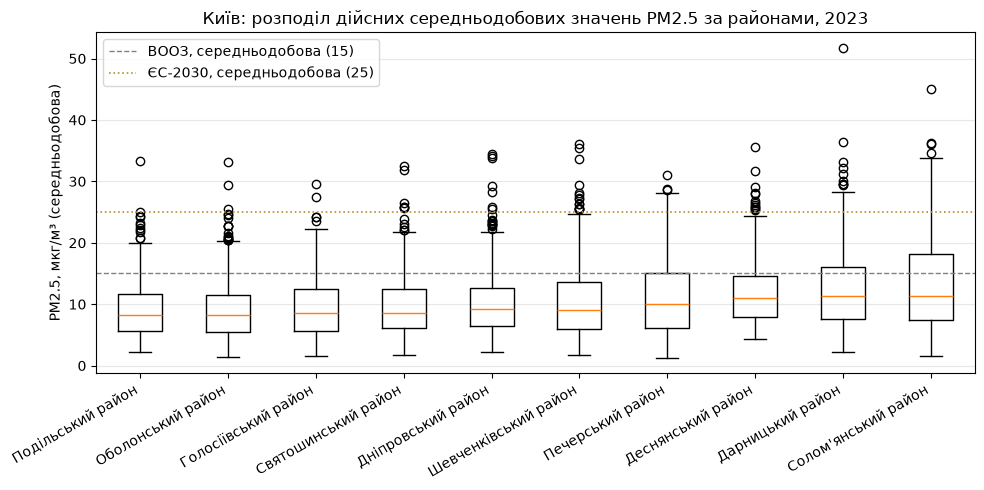

In [24]:
# Власний графік 1: розподіл середньодобових значень за районами
fig, ax = plt.subplots(figsize=(10, 5))
ax.boxplot([daily_mean[n].dropna() for n in order])
ax.set_xticks(range(1, len(order) + 1), order,
              rotation=30, ha="right")
ax.axhline(WHO_DAILY, ls="--", color="gray", lw=1,
           label="ВООЗ, середньодобова (15)")
ax.axhline(EU_DAILY_2030, ls=":", color="#B8912F", lw=1.2,
           label="ЄС-2030, середньодобова (25)")
ax.set_ylabel("PM2.5, мкг/м³ (середньодобова)")
ax.set_title(f"{CITY_NAME}: розподіл дійсних середньодобових "
             f"значень PM2.5 за районами, {YEAR}")
ax.legend()
ax.grid(alpha=0.3, axis="y")
fig.tight_layout()
fig.savefig(FIGURES / "district_daily_boxplot.png", dpi=150)
plt.show()

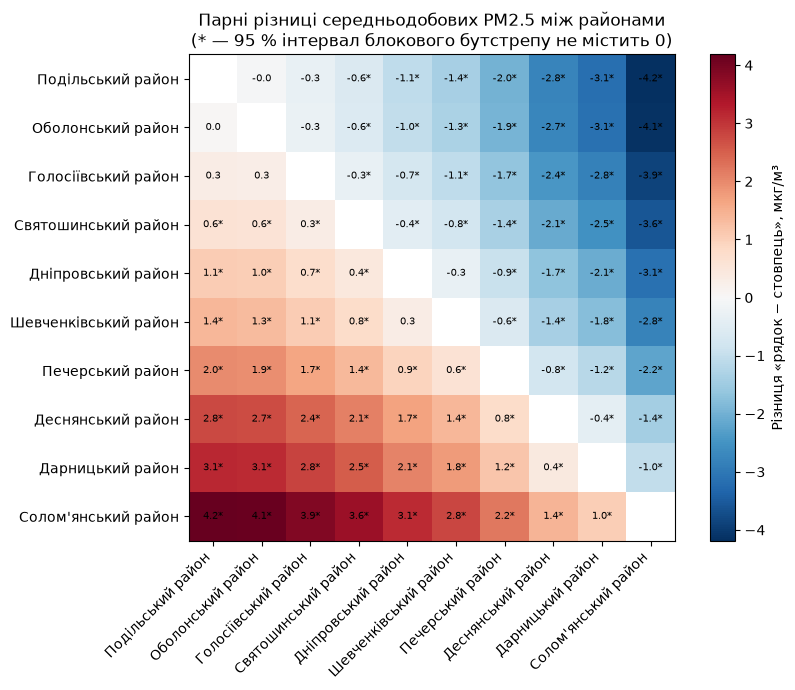

In [25]:
# Власний графік 2: матриця парних різниць районів
fig, ax = plt.subplots(figsize=(9, 7))
lim = np.nanmax(np.abs(mean_diff.to_numpy()))
im = ax.imshow(mean_diff.to_numpy(dtype=float), cmap="RdBu_r",
               vmin=-lim, vmax=lim)
ax.set_xticks(range(len(order)), order, rotation=45, ha="right")
ax.set_yticks(range(len(order)), order)
for i, a in enumerate(order):
    for j, b in enumerate(order):
        if i != j:
            mark = "*" if signif.loc[a, b] else ""
            ax.text(j, i, f"{mean_diff.loc[a, b]:.1f}{mark}",
                    ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax, label="Різниця «рядок − стовпець», мкг/м³")
ax.set_title("Парні різниці середньодобових PM2.5 між районами\n"
             "(* — 95 % інтервал блокового бутстрепу не містить 0)")
fig.tight_layout()
fig.savefig(FIGURES / "district_pairwise_diff.png", dpi=150)
plt.show()

In [26]:
# 5. Звірка з міським рядом Києва (той самий метод, що в прикладі)
city_file = RAW / f"saveecobot_cities_pm25_and_aqi_pm25_{YEAR}.csv"
if city_file.exists():
    city = pd.read_csv(city_file, encoding="utf-8",
                       usecols=["city_id", "pm25", "logged_at"],
                       dtype={"city_id": "int32", "pm25": "float64",
                              "logged_at": "string"})
    city = city[city["city_id"] == CITY_ID].copy()
    city["logged_at"] = pd.to_datetime(city["logged_at"],
                                       format="%Y-%m-%d %H:%M:%S")
    city = (city.drop_duplicates(subset=["logged_at"])
                .loc[lambda d: d["pm25"].between(0, 1000)]
                .sort_values("logged_at")
                .set_index("logged_at"))
    city_daily = city["pm25"].resample("D").agg(["mean", "count"])
    city_daily.loc[city_daily["count"] < VALID_HOURS, "mean"] = np.nan
    print(f"Міський ряд Києва: {city_daily['mean'].mean():.1f} мкг/м³, "
          f"дійсних діб {int((city_daily['count'] >= VALID_HOURS).sum())}")
    print(f"Середнє 10 районів: {annual.mean():.1f} мкг/м³; "
          f"діапазон районів {annual.min():.1f}–{annual.max():.1f}")
else:
    print("Файл міст за", YEAR, "не знайдено — звірку пропущено")

Міський ряд Києва: 10.7 мкг/м³, дійсних діб 365
Середнє 10 районів: 10.8 мкг/м³; діапазон районів 9.3–13.5


## Додатково (крок 14): чутливість індикатора до порогу дійсної доби

Як зміняться середньорічне значення і кількість дійсних діб, якщо поріг замість 18 годин
становитиме 12 або 22 години.

In [27]:
rows = []
for thr in [12, 18, 22]:
    ok = daily_count >= thr
    mean_thr = wide.resample("D").mean().where(ok).mean()
    rows.append(pd.DataFrame({"поріг_год": thr,
                              "середньорічна": mean_thr,
                              "дійсних_діб": ok.sum()}))
sensitivity = (pd.concat(rows).rename_axis("район").reset_index()
               .pivot(index="район", columns="поріг_год",
                      values=["середньорічна", "дійсних_діб"])
               .reindex(order))
sensitivity["дійсних_діб"] = sensitivity["дійсних_діб"].astype(int)
sensitivity.round(2)

середньорічна               дійсних_діб          
поріг_год                       12     18     22          12   18   22
район                                                                 
Подільський район             9.28   9.28   9.27         365  365  364
Оболонський район             9.32   9.32   9.32         365  365  365
Голосіївський район           9.58   9.58   9.58         365  365  365
Святошинський район           9.90   9.90   9.90         365  365  365
Дніпровський район           10.33  10.33  10.33         365  365  365
Шевченківський район         10.65  10.65  10.65         365  365  365
Печерський район             11.25  11.25  11.23         365  365  363
Деснянський район            12.03  12.01  11.86         365  364  358
Дарницький район             12.42  12.42  12.42         365  365  365
Солом'янський район          13.46  13.46  13.46         365  365  365

### Крок 13. Висновки й обмеження

Висновки записуються у звіт `README.md` з опорою на числа з таблиць індикаторів, повноти, творчої
частини та графіки. Обмеження: недорогі сенсори громадян, а не референтні станції; кількість і
розташування сенсорів у районах невідомі й змінюються; позначки часу в місцевому часі (перехід на
літній час); можливі пропуски через відключення електроенергії.